# 30 — Warning precision–recall trade-off at shared calibration budgets

MA3 primary definition unchanged. Existing forecasts only. Thresholds use Apr30–Aug28 2020; assessment Sep1–Dec28. Previously viewed assessment is exploratory. Equal calibration budgets do not ensure equal later realized false-warning rates.

Run the final cell to inspect saved results without rerunning the analysis.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if (ROOT/"Weikun").is_dir():ROOT=ROOT/"Weikun"
OUTPUT=ROOT/"warning_budget_outputs"/"budget_comparison_20261101"
print(OUTPUT.resolve())

C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun\warning_budget_outputs\budget_comparison_20261101


In [2]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

MODELS=['Dynamic Panel FE','XGBoost','Random Forest']
BUDGETS=[0.,.05,.1,.25,.5,1.,2.]

def evaluate(score,eligible,event_days,origins,threshold,details=False):
    # Ordinal day arrays, one-to-one matching, issue cooldown seven calendar days.
    n=score.shape[0]; exposure=int(eligible.sum()); rows=[]; ne=tp=fp=early=0; leads=[]
    for z in range(n):
        ev=[int(d) for d in event_days[z] if np.any(eligible[z]&((d-origins)>=1)&((d-origins)<=3))]
        ne+=len(ev); matched=set(); last=-1000000
        for k in np.flatnonzero(eligible[z]&(score[z]>threshold)):
            d=int(origins[k])
            if d-last<7:continue
            last=d
            choices=[e for e in ev if e not in matched and 1<=e-d<=3]
            target=min(choices) if choices else None
            if target is None:fp+=1
            else:
                matched.add(target);tp+=1;leads.append(target-d);early+=int(target-d>=2)
            if details:rows.append((z,d,target,target-d if target is not None else np.nan))
    return dict(events=ne,detected_events=tp,false_warnings=fp,warnings=tp+fp,
                event_recall=tp/ne if ne else np.nan,warning_precision=tp/(tp+fp) if tp+fp else np.nan,
                recall_at_least_2_days=early/ne if ne else np.nan,
                false_warnings_per_1000_at_risk_zip_days=fp*1000/exposure,
                at_risk_zip_days=exposure,mean_lead_days=float(np.mean(leads)) if leads else np.nan),rows

def run(root,output):
    root,output=Path(root),Path(output);output.mkdir(parents=True,exist_ok=True);fig=output/'figures';fig.mkdir(exist_ok=True)
    source=root/'outbreak_task_outputs'/'case_surge_v1_20261101'
    if not source.exists():raise FileNotFoundError(source)
    catalog=pd.read_csv(source/'event_catalog_2020.csv',dtype={'zip':'string'},parse_dates=['event_date'])
    grids=[];chosen=[];metrics=[];reference=None;hashes={}
    for model in MODELS:
        tag=model.lower().replace(' ','_');path=source/(tag+'_risk_scores.csv.gz');hashes[path.name]=hashlib.sha256(path.read_bytes()).hexdigest()
        df=pd.read_csv(path,dtype={'zip':'string'},parse_dates=['forecast_origin'])
        ids=np.sort(df.zip.unique());dates=np.sort(df.forecast_origin.unique()).astype('datetime64[D]');orig=dates.astype(int)
        score=df.pivot(index='zip',columns='forecast_origin',values='risk_score').reindex(index=ids,columns=dates).to_numpy()
        eligible=df.pivot(index='zip',columns='forecast_origin',values='eligible').reindex(index=ids,columns=dates).to_numpy(dtype=bool)
        truth=df.pivot(index='zip',columns='forecast_origin',values='event_in_next_3_days').reindex(index=ids,columns=dates).to_numpy(dtype=bool)
        if reference is None:reference=(ids,dates,eligible,truth)
        else:
            for a,b in zip(reference,(ids,dates,eligible,truth)):assert np.array_equal(a,b)
        event_days=[catalog.loc[catalog.zip.eq(z),'event_date'].to_numpy().astype('datetime64[D]').astype(int) for z in ids]
        cal=(dates>=np.datetime64('2020-04-30'))&(dates<=np.datetime64('2020-08-28'))
        assess=(dates>=np.datetime64('2020-09-01'))&(dates<=np.datetime64('2020-12-28'))
        assert dates[cal].max()+np.timedelta64(3,'D')<dates[assess].min()
        positive=score[:,cal][eligible[:,cal]&(score[:,cal]>0)]
        thresholds=np.unique(np.r_[0,np.quantile(positive,np.linspace(0,1,81)),.25,.5,1,2,3,5,10,np.inf])
        local=[]
        for threshold in thresholds:
            met,_=evaluate(score[:,cal],eligible[:,cal],event_days,orig[cal],threshold)
            local.append(dict(model=model,threshold=threshold,**met))
        grids.extend(local)
        # No assumed monotonicity: cooldown can change event matching at each threshold.
        for budget in BUDGETS:
            allowed=[r for r in local if r['false_warnings_per_1000_at_risk_zip_days']<=budget+1e-12]
            pick=sorted(allowed,key=lambda r:(-r['event_recall'],r['false_warnings_per_1000_at_risk_zip_days'],r['threshold']))[0]
            chosen.append(dict(budget_per_1000=budget,**pick))
            for phase,mask in [('calibration',cal),('assessment',assess)]:
                met,rows=evaluate(score[:,mask],eligible[:,mask],event_days,orig[mask],pick['threshold'],True)
                metrics.append(dict(model=model,budget_per_1000=budget,threshold=pick['threshold'],phase=phase,**met))
                alarms=pd.DataFrame(rows,columns=['region_index','origin_day','event_day','lead_days'])
                if len(alarms):
                    alarms['zip']=ids[alarms.region_index.to_numpy()]
                    alarms['forecast_origin']=pd.to_datetime(alarms.origin_day,unit='D').dt.strftime('%Y-%m-%d')
                    alarms['matched_event_date']=pd.to_datetime(alarms.event_day,unit='D').dt.strftime('%Y-%m-%d')
                alarms.to_csv(output/f'{tag}_budget_{budget:g}_{phase}_warnings.csv',index=False)
        # Saved zero-threshold results must exactly reproduce Notebook27.
        old=pd.read_csv(source/'warning_metrics.csv');old=old[(old.model==model)&(old.phase=='assessment')].iloc[0]
        check,_=evaluate(score[:,assess],eligible[:,assess],event_days,orig[assess],0)
        assert check['events']==old.events and check['detected_events']==old.detected_events
        assert check['false_warnings']==old.false_warning_episodes
        print('Finished:',model,flush=True)
    g=pd.DataFrame(grids);c=pd.DataFrame(chosen);m=pd.DataFrame(metrics);a=m[m.phase.eq('assessment')].copy()
    g.to_csv(output/'calibration_threshold_grid.csv',index=False);c.to_csv(output/'calibration_selected_thresholds.csv',index=False)
    m.to_csv(output/'metrics_by_budget.csv',index=False);a.to_csv(output/'assessment_by_budget.csv',index=False)
    plt.rcParams.update({'font.family':'Arial','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
    colors=['#64748B','#2563EB','#087F78']
    f,axes=plt.subplots(1,3,figsize=(15,4.5))
    for model,color in zip(MODELS,colors):
        q=a[a.model.eq(model)].sort_values('budget_per_1000')
        for ax,col,title in zip(axes,['event_recall','warning_precision','recall_at_least_2_days'],['Event recall','Warning precision','Recall with at least 2-day lead']):
            ax.plot(q.budget_per_1000,q[col],'o-',color=color,label=model);ax.set(xlabel='Calibration budget: false warnings / 1,000 at-risk ZIP-days',ylabel=title,ylim=(0,1));ax.grid(alpha=.2)
    axes[0].legend(fontsize=9);f.suptitle('Same calibration budgets; Sep–Dec 2020 exploratory assessment',fontsize=14)
    f.tight_layout();f.savefig(fig/'01_budget_tradeoff.png',dpi=200,bbox_inches='tight');plt.close(f)
    f,axes=plt.subplots(1,2,figsize=(11,4.5))
    for model,color in zip(MODELS,colors):
        q=a[a.model.eq(model)].sort_values('budget_per_1000')
        axes[0].plot(q.false_warnings_per_1000_at_risk_zip_days,q.event_recall,'o-',label=model,color=color)
        axes[1].plot(q.budget_per_1000,q.false_warnings_per_1000_at_risk_zip_days,'o-',label=model,color=color)
    axes[0].set(xlabel='Realized assessment false warnings / 1,000 at-risk ZIP-days',ylabel='Event recall',ylim=(0,1))
    axes[1].plot([0,2],[0,2],'--',color='gray',label='Budget reference')
    axes[1].set(xlabel='Calibration budget / 1,000 at-risk ZIP-days',ylabel='Realized assessment false-warning rate')
    for ax in axes:ax.grid(alpha=.2);ax.legend(fontsize=8)
    f.suptitle('A calibration budget is not a guarantee of future false-warning rates');f.tight_layout();f.savefig(fig/'02_realized_false_warning_rates.png',dpi=200,bbox_inches='tight');plt.close(f)
    protocol=dict(primary_definition='Notebook27 MA3 unchanged',budgets_per_1000_at_risk_zip_days=BUDGETS,threshold_candidates='0, calibration-only positive-score quantiles (81 positions), fixed values .25,.5,1,2,3,5,10 and infinity; never negative',selection='maximize calibration event recall subject to budget; ties lower realized false warning rate, then lower threshold',calibration='Apr30-Aug28 2020 origins, targets end Aug31',assessment='Sep1-Dec28 2020, previously inspected, exploratory',warning_policy='score strictly greater than threshold; seven-day issue cooldown; one-to-one matching before confirmation by1..3days',early_recall='events detected at least2days before confirmation / all eligible events; not conditional on detection',comparison='same labels,585ZIPs,dates and horizon for all models; calibration budget equal, realized assessment rate may differ',limitations=['quantile grid is finite','calibration has226events vs1131assessment events; epidemic activity shifts','no inference of pre-biological-onset warning','no formal statistical superiority tests','no model refit; no2021-2023outcomes'],source_sha256=hashes)
    (output/'comparison_definition.json').write_text(json.dumps(protocol,indent=2),encoding='utf-8')
    report='# Notebook30：相同误报预算下比较模型\n\n先看 figures/01_budget_tradeoff.png 和 assessment_by_budget.csv。\n\n主事件定义仍为3天。用4—8月选择阈值，9—12月只计算表现。每1000个可预警ZIP日允许0/.05/.1/.25/.5/1/2次误报。一个ZIP的1000天或多个ZIP累计1000天均是相同暴露单位，不是1000个事件，也不是误报百分比。阈值不允许小于0，以保留预测满足病例激增条件这一要求。\n\n每个预算下选择校准期事件检出率最高的阈值。冷却期会使表现不完全单调，所以逐个阈值实际计算，不假定单调。相同的是校准预算，不保证后续实际误报率相同；必须结合02图。\n\n'+a[['model','budget_per_1000','threshold','event_recall','warning_precision','recall_at_least_2_days','false_warnings_per_1000_at_risk_zip_days','false_warnings','detected_events']].to_string(index=False)+'\n\n0预算仅意味着校准期没有误报，不意味着后续不会误报。非负阈值下若宽松预算已经饱和，更多预算不一定提高检出率。9—12月此前已经查看，属于探索性分析，不能称为全新独立测试。当前不按后续期最优分数选择最终预算或最终模型。\n'
    (output/'RESULTS_CN.md').write_text(report,encoding='utf-8')
    (output/'verification.json').write_text(json.dumps(dict(same_cohort_verified=True,notebook27_zero_threshold_reproduced=True,calibration_targets_before_assessment=True,no_model_refit=True,regions=len(ids),assessment_events=int(a.events.iloc[0])),indent=2),encoding='utf-8')
    print(a[['model','budget_per_1000','event_recall','warning_precision','recall_at_least_2_days','false_warnings_per_1000_at_risk_zip_days']].to_string(index=False));return m


In [3]:
metrics=run(ROOT,OUTPUT)
display(metrics)

Finished: Dynamic Panel FE
Finished: XGBoost
Finished: Random Forest
           model  budget_per_1000  event_recall  warning_precision  recall_at_least_2_days  false_warnings_per_1000_at_risk_zip_days
Dynamic Panel FE             0.00      0.487179           0.850309                0.072502                                  1.746458
Dynamic Panel FE             0.05      0.616269           0.779642                0.122900                                  3.546929
Dynamic Panel FE             0.10      0.648983           0.767782                0.143236                                  3.997047
Dynamic Panel FE             0.25      0.740937           0.675262                0.197171                                  7.255901
Dynamic Panel FE             0.50      0.786030           0.679144                0.201592                                  7.561981
Dynamic Panel FE             1.00      0.786030           0.679144                0.201592                                  7.561981


,model,budget_per_1000,threshold,phase,events,detected_events,false_warnings,warnings,event_recall,warning_precision,recall_at_least_2_days,false_warnings_per_1000_at_risk_zip_days,at_risk_zip_days,mean_lead_days
0,Dynamic Panel FE,0.00,0.360541,calibration,226,70,0,70,0.309735,1.000000,0.000000,0.000000,68537,1.000000
1,Dynamic Panel FE,0.00,0.360541,assessment,1131,551,97,648,0.487179,0.850309,0.072502,1.746458,55541,1.174229
2,Dynamic Panel FE,0.05,0.209586,calibration,226,110,3,113,0.486726,0.973451,0.022124,0.043772,68537,1.054545
3,Dynamic Panel FE,0.05,0.209586,assessment,1131,697,197,894,0.616269,0.779642,0.122900,3.546929,55541,1.236729
4,Dynamic Panel FE,0.10,0.164428,calibration,226,114,6,120,0.504425,0.950000,0.022124,0.087544,68537,1.052632
5,Dynamic Panel FE,0.10,0.164428,assessment,1131,734,222,956,0.648983,0.767782,0.143236,3.997047,55541,1.262943
6,Dynamic Panel FE,0.25,0.009137,calibration,226,138,16,154,0.610619,0.896104,0.030973,0.233451,68537,1.057971
7,Dynamic Panel FE,0.25,0.009137,assessment,1131,838,403,1241,0.740937,0.675262,0.197171,7.255901,55541,1.316229
8,Dynamic Panel FE,0.50,0.000000,calibration,226,164,21,185,0.725664,0.886486,0.030973,0.306404,68537,1.048780
9,Dynamic Panel FE,0.50,0.000000,assessment,1131,889,420,1309,0.786030,0.679144,0.201592,7.561981,55541,1.304837


# 先看这里：Notebook30

## 这次回答什么问题？
给三个模型相同的校准期误报预算，比较之后的事件检出率、预警正确比例和至少提前2天检出率。没有重新训练模型，也没有改3天事件定义。

## 先看三个文件
1. figures/01_budget_tradeoff.png：报警标准越严格，通常预警正确比例上升，但检出率下降。
2. figures/02_realized_false_warning_rates.png：相同校准预算不保证后续实际误报率相同。左图是描述性已实现表现，不能在此挑阈值再称为独立测试。
3. assessment_by_budget.csv：精确数字。

## 一个用于理解的例子（不是最终推荐预算）
校准预算为每1000个可预警ZIP日0.25次误报时，9—12月结果为：

|模型|事件检出率|预警正确比例|至少提前2天检出率|实际误报/1000 ZIP日|
|---|---:|---:|---:|---:|
|Dynamic Panel|74.1%|67.5%|19.7%|7.26|
|XGBoost|72.9%|83.7%|8.8%|2.90|
|Random Forest|66.2%|81.1%|12.3%|3.15|

XGBoost在这个预算下预警更准、实际误报较少；Dynamic Panel捕捉更多且至少提前2天的事件比例更高，但误报也多。模型选择取决于代价和提前量，不能只看一个指标。

## 最重要的新发现
4—8月阈值在9—12月没有维持原有误报预算，提示报警策略跨阶段的稳定性需要分析；不能仅归因于某个模型，也未证明原因。即使校准预算为0，后续仍然出现误报。

预算的单位是可预警的地区×日期。例如100个ZIP各10天就是1000 ZIP日。0.25/1000约等于每4000 ZIP日一次误报，不是25%误报，也不是每1000次事件误报。

## 如何运行
打开30_compare_warning_budgets.ipynb。最后的“查看已保存结果”可以直接查看，无需重跑；完整运行只读取Notebook27输出，生成本文件夹。

## 下一步
先约定允许的误报成本或漏报成本，再冻结报警策略。可用开发期内的按月/时间块检查校准稳定性。不要根据9—12月最高分选择最终预算。当前结果是探索性回顾分析，事件为研究定义的病例激增，提前量相对于第二个异常日的确认日。


,model,budget_per_1000,threshold,phase,events,detected_events,false_warnings,warnings,event_recall,warning_precision,recall_at_least_2_days,false_warnings_per_1000_at_risk_zip_days,at_risk_zip_days,mean_lead_days
0,Dynamic Panel FE,0.00,0.360541,assessment,1131,551,97,648,0.487179,0.850309,0.072502,1.746458,55541,1.174229
1,Dynamic Panel FE,0.05,0.209586,assessment,1131,697,197,894,0.616269,0.779642,0.122900,3.546929,55541,1.236729
2,Dynamic Panel FE,0.10,0.164428,assessment,1131,734,222,956,0.648983,0.767782,0.143236,3.997047,55541,1.262943
3,Dynamic Panel FE,0.25,0.009137,assessment,1131,838,403,1241,0.740937,0.675262,0.197171,7.255901,55541,1.316229
4,Dynamic Panel FE,0.50,0.000000,assessment,1131,889,420,1309,0.786030,0.679144,0.201592,7.561981,55541,1.304837
5,Dynamic Panel FE,1.00,0.000000,assessment,1131,889,420,1309,0.786030,0.679144,0.201592,7.561981,55541,1.304837
6,Dynamic Panel FE,2.00,0.000000,assessment,1131,889,420,1309,0.786030,0.679144,0.201592,7.561981,55541,1.304837
7,XGBoost,0.00,0.395902,assessment,1131,388,19,407,0.343059,0.953317,0.015031,0.342090,55541,1.048969
8,XGBoost,0.05,0.236564,assessment,1131,544,56,600,0.480990,0.906667,0.030062,1.008264,55541,1.066176
9,XGBoost,0.10,0.167209,assessment,1131,602,73,675,0.532272,0.891852,0.045093,1.314344,55541,1.094684


,budget_per_1000,model,threshold,events,detected_events,false_warnings,warnings,event_recall,warning_precision,recall_at_least_2_days,false_warnings_per_1000_at_risk_zip_days,at_risk_zip_days,mean_lead_days
0,0.00,Dynamic Panel FE,0.360541,226,70,0,70,0.309735,1.000000,0.000000,0.000000,68537,1.000000
1,0.05,Dynamic Panel FE,0.209586,226,110,3,113,0.486726,0.973451,0.022124,0.043772,68537,1.054545
2,0.10,Dynamic Panel FE,0.164428,226,114,6,120,0.504425,0.950000,0.022124,0.087544,68537,1.052632
3,0.25,Dynamic Panel FE,0.009137,226,138,16,154,0.610619,0.896104,0.030973,0.233451,68537,1.057971
4,0.50,Dynamic Panel FE,0.000000,226,164,21,185,0.725664,0.886486,0.030973,0.306404,68537,1.048780
5,1.00,Dynamic Panel FE,0.000000,226,164,21,185,0.725664,0.886486,0.030973,0.306404,68537,1.048780
6,2.00,Dynamic Panel FE,0.000000,226,164,21,185,0.725664,0.886486,0.030973,0.306404,68537,1.048780
7,0.00,XGBoost,0.395902,226,66,0,66,0.292035,1.000000,0.004425,0.000000,68537,1.015152
8,0.05,XGBoost,0.236564,226,94,3,97,0.415929,0.969072,0.000000,0.043772,68537,1.000000
9,0.10,XGBoost,0.167209,226,109,6,115,0.482301,0.947826,0.013274,0.087544,68537,1.036697


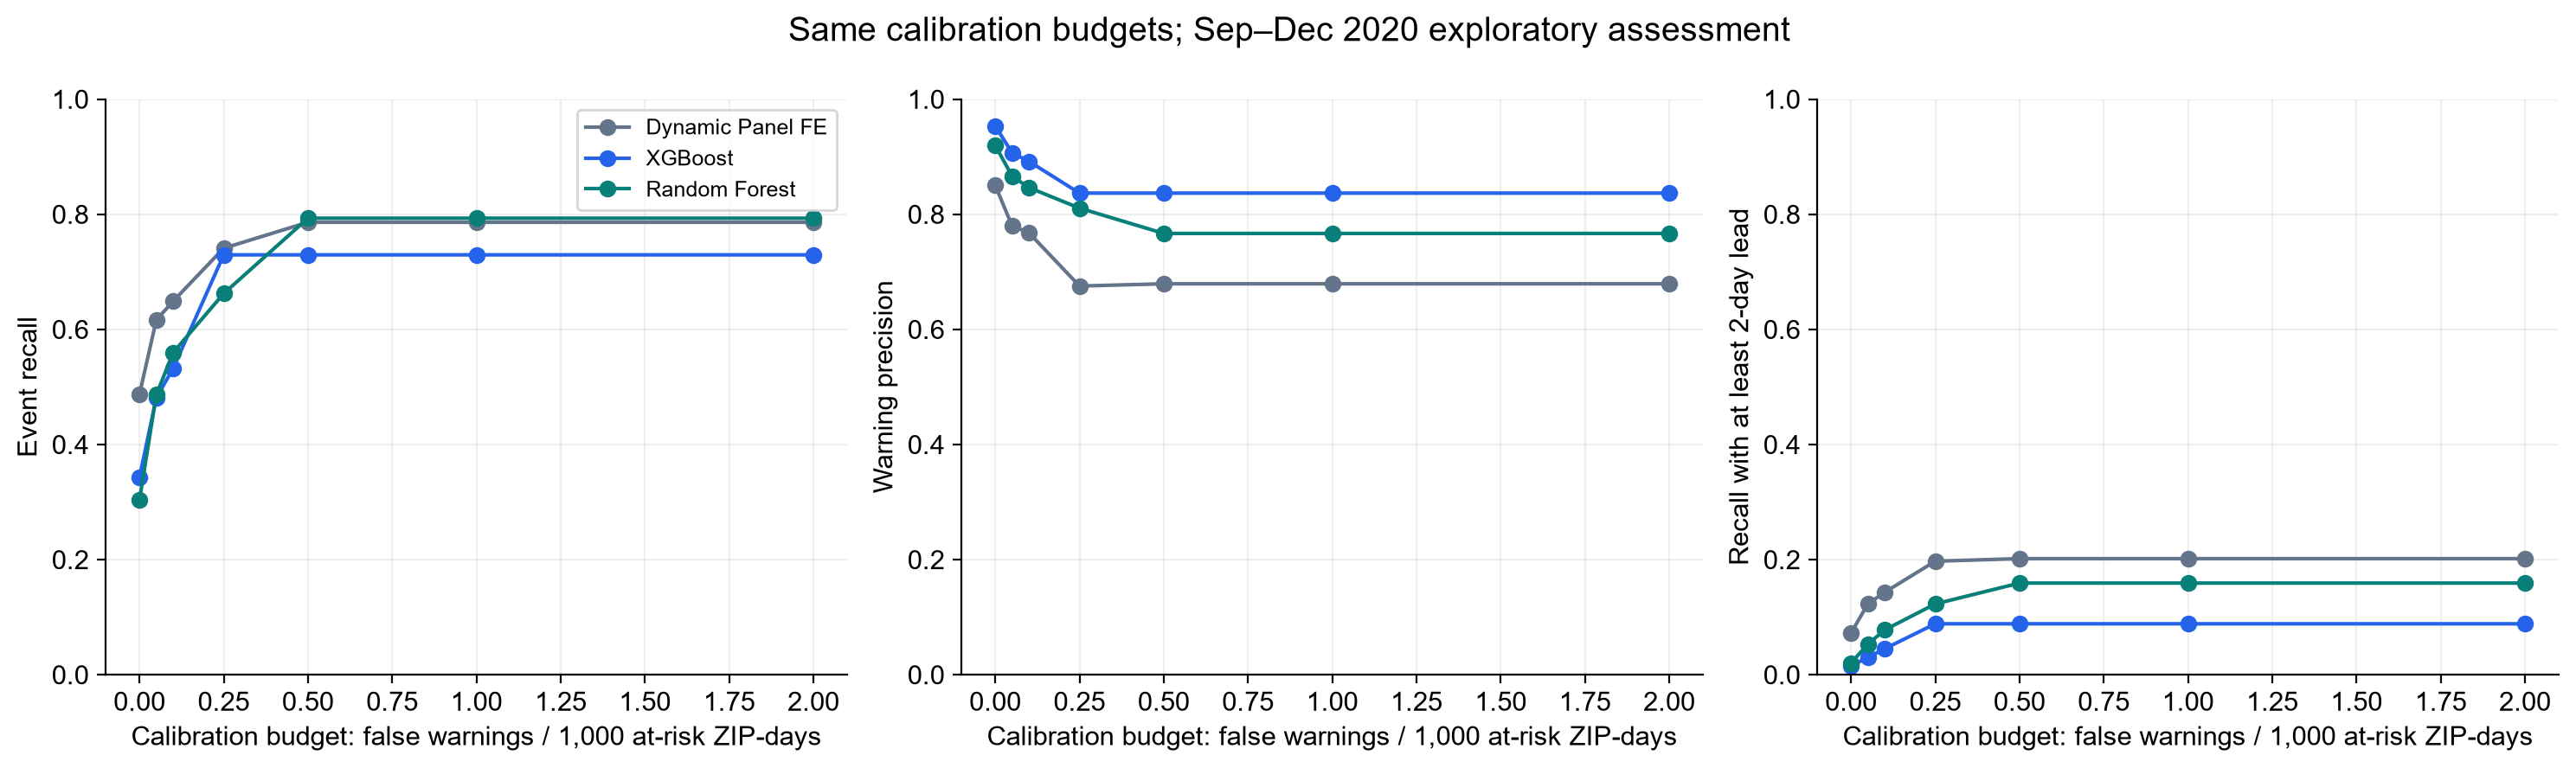

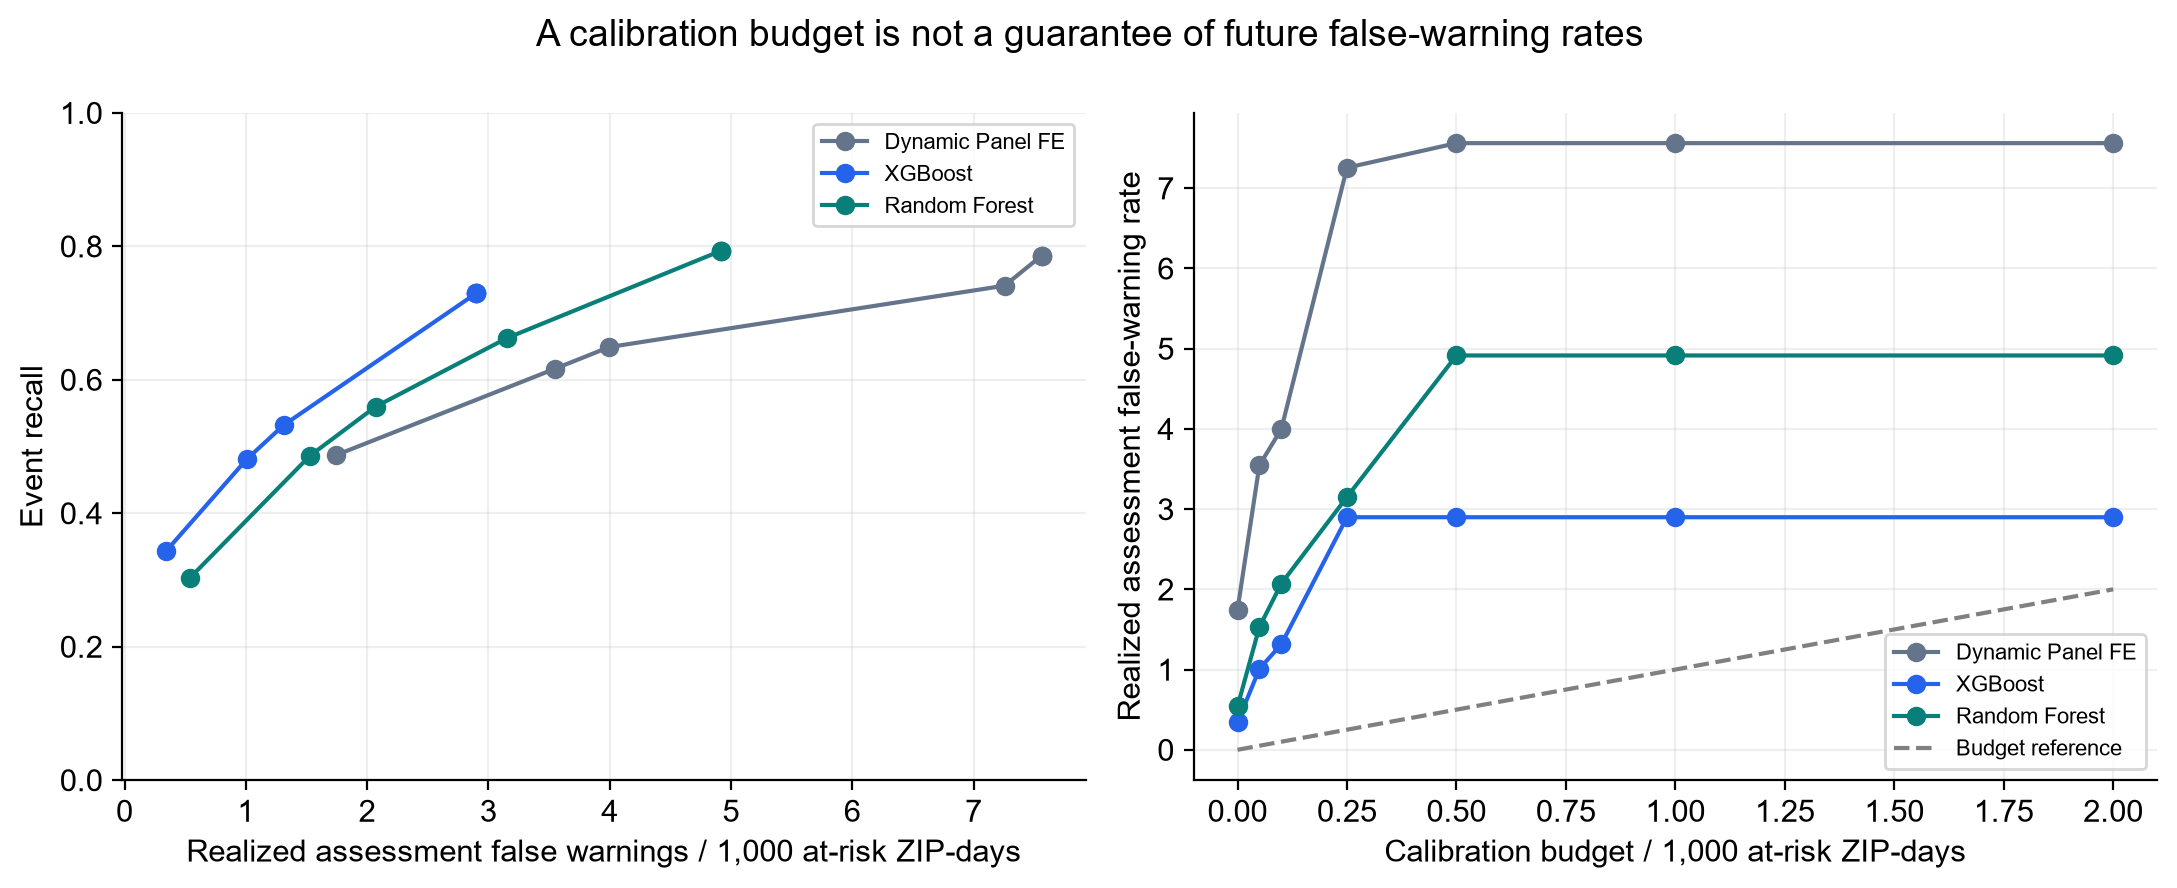

In [4]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv(OUTPUT/"assessment_by_budget.csv"))
display(pd.read_csv(OUTPUT/"calibration_selected_thresholds.csv"))
for name in ["01_budget_tradeoff.png","02_realized_false_warning_rates.png"]:
    display(Image(filename=str(OUTPUT/"figures"/name)))